In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
customers=pd.read_csv(r"C:\Users\TUHIN\Desktop\Banking Risk Analytics Project\Banking_Risk_Analytics_Dataset-Branches,Banking_Risk_Analytics_Dataset-Customers,Banking_Risk_A[...]\Banking_Risk_Analytics_Dataset-Customers.csv")
loans=pd.read_csv(r"C:\Users\TUHIN\Desktop\Banking Risk Analytics Project\Banking_Risk_Analytics_Dataset-Branches,Banking_Risk_Analytics_Dataset-Customers,Banking_Risk_A[...]\Banking_Risk_Analytics_Dataset-Loans.csv")
transaction=pd.read_csv(r"C:\Users\TUHIN\Desktop\Banking Risk Analytics Project\Banking_Risk_Analytics_Dataset-Branches,Banking_Risk_Analytics_Dataset-Customers,Banking_Risk_A[...]\Banking_Risk_Analytics_Dataset-Transactions.csv")

print(customers.sample(1))
print(loans.sample(1))
print(transaction.sample(1))

     Customer_Id  Age Gender         City Occupation      Education  \
3497      C03498   52   Male  Bhubaneswar   Salaried  Post Graduate   

      Annual_income  Credit_score Customer_segment Branch_id  Unnamed: 10  \
3497         768000           771      Mass Market     BR006          NaN   

      Unnamed: 11  Unnamed: 12 Unnamed: 13  Unnamed: 14  
3497          NaN          NaN         NaN          NaN  
     loan_id Customer_Id      loan_type  application_date  loan_amount  \
801  L000802      C01634  Personal Loan  13-02-2025 00:00       300000   

     interest_rate  tenure_months loan_status  outstanding_amount  \
801           9.03            120      Active           264990.46   

     credit_score  annual_income risk_band  debt_to_income_proxy  Unnamed: 13  \
801           759         131000       Low                  2.02          NaN   

     Unnamed: 14  
801          NaN  
      transaction_id Customer_Id  transaction_date transaction_type    amount  \
24451       T002

In [7]:
customers["Customer_Id"].duplicated().sum()

np.int64(0)

In [8]:
customers.dtypes

Customer_Id          object
Age                   int64
Gender               object
City                 object
Occupation           object
Education            object
Annual_income         int64
Credit_score          int64
Customer_segment     object
Branch_id            object
Unnamed: 10         float64
Unnamed: 11         float64
Unnamed: 12         float64
Unnamed: 13          object
Unnamed: 14         float64
dtype: object

In [9]:
loans["Customer_Id"].duplicated().sum()

np.int64(2898)

In [10]:
customers.isnull().sum()/len(customers)*100

Customer_Id           0.00
Age                   0.00
Gender                0.00
City                  0.00
Occupation            0.00
Education             0.00
Annual_income         0.00
Credit_score          0.00
Customer_segment      0.00
Branch_id             0.00
Unnamed: 10         100.00
Unnamed: 11         100.00
Unnamed: 12         100.00
Unnamed: 13          99.98
Unnamed: 14          99.98
dtype: float64

In [11]:
loans.isnull().sum()/len(loans)*100

loan_id                   0.000000
Customer_Id               0.000000
loan_type                 0.000000
application_date          0.000000
loan_amount               0.000000
interest_rate             0.000000
tenure_months             0.000000
loan_status               0.000000
outstanding_amount        0.000000
credit_score              0.000000
annual_income             0.000000
risk_band                 0.000000
debt_to_income_proxy      0.000000
Unnamed: 13             100.000000
Unnamed: 14              99.984615
dtype: float64

In [12]:
transaction.isnull().sum()/len(transaction)*100

transaction_id        0.0
Customer_Id           0.0
transaction_date      0.0
transaction_type      0.0
amount                0.0
channel               0.0
transaction_status    0.0
dtype: float64

In [13]:
loans.dtypes

loan_id                  object
Customer_Id              object
loan_type                object
application_date         object
loan_amount               int64
interest_rate           float64
tenure_months             int64
loan_status              object
outstanding_amount      float64
credit_score              int64
annual_income             int64
risk_band                object
debt_to_income_proxy    float64
Unnamed: 13             float64
Unnamed: 14             float64
dtype: object

In [14]:
transaction.dtypes

transaction_id         object
Customer_Id            object
transaction_date       object
transaction_type       object
amount                float64
channel                object
transaction_status     object
dtype: object

In [15]:
customers = customers.loc[:, ~customers.columns.str.startswith("Unnamed")]
loans = loans.loc[:, ~loans.columns.str.startswith("Unnamed")]

In [16]:
customers.dtypes

Customer_Id         object
Age                  int64
Gender              object
City                object
Occupation          object
Education           object
Annual_income        int64
Credit_score         int64
Customer_segment    object
Branch_id           object
dtype: object

In [17]:
loans.dtypes

loan_id                  object
Customer_Id              object
loan_type                object
application_date         object
loan_amount               int64
interest_rate           float64
tenure_months             int64
loan_status              object
outstanding_amount      float64
credit_score              int64
annual_income             int64
risk_band                object
debt_to_income_proxy    float64
dtype: object

In [18]:
customers["Customer_Id"].nunique()

5000

In [19]:
loans["Customer_Id"].nunique()

3602

In [20]:
transaction["Customer_Id"].nunique()

4988

In [21]:
loan_summary = loans.groupby("Customer_Id").agg(total_loans=("loan_id", "count"),
                total_loan_amount=("loan_amount", "sum"),
                total_outstanding=("outstanding_amount", "sum"),
                avg_interest_rate=("interest_rate", "mean"),
                avg_loan_amount=("loan_amount", "mean")
).reset_index()
loan_summary.sample(5)

,Customer_Id,total_loans,total_loan_amount,total_outstanding,avg_interest_rate,avg_loan_amount
3169,C04407,3,400000,44479.14,12.446667,1.333333e+05
1417,C01961,2,3500000,0.00,14.935000,1.750000e+06
2352,C03273,2,1100000,231413.84,9.790000,5.500000e+05
2740,C03833,1,500000,355368.67,10.610000,5.000000e+05
745,C01050,2,600000,78053.79,15.465000,3.000000e+05


In [22]:
transaction_summary = transaction.groupby("Customer_Id").agg(total_transactions=("transaction_id", "count"),
                      total_transaction_amount=("amount", "sum"),
                      avg_transaction_amount=("amount", "mean")
).reset_index()
transaction_summary.sample(3)

,Customer_Id,total_transactions,total_transaction_amount,avg_transaction_amount
2886,C02894,12,81035.87,6752.989167
2946,C02954,3,23012.53,7670.843333
2711,C02719,3,45477.85,15159.283333


In [23]:
successful_transactions = (transaction[transaction["transaction_status"] == "Success"].groupby("Customer_Id").size()
    .reset_index(name="successful_transactions"))

failed_transactions = (transaction[transaction["transaction_status"] != "Success"].groupby("Customer_Id")
    .size().reset_index(name="failed_transactions"))

successful_transactions.sample(5)

,Customer_Id,successful_transactions
2491,C02500,8
3113,C03123,4
1014,C01019,3
4939,C04954,5
4186,C04197,6


In [24]:
failed_transactions.sample(5)

,Customer_Id,failed_transactions
164,C00919,1
586,C02956,1
443,C02263,1
684,C03501,1
172,C00952,1


In [25]:
customer_loans = customers.merge(loan_summary,on="Customer_Id",how="left")
customer_loans.sample(3)

,Customer_Id,Age,Gender,City,Occupation,Education,Annual_income,Credit_score,Customer_segment,Branch_id,total_loans,total_loan_amount,total_outstanding,avg_interest_rate,avg_loan_amount
2147,C02148,62,Male,Pune,Salaried,Graduate,902000,703,Affluent,BR006,4.0,3200000.0,1204899.81,13.005000,8.000000e+05
1655,C01656,34,Female,Hyderabad,Salaried,Under Graduate,310000,815,Mass Market,BR007,3.0,4000000.0,2252874.10,15.443333,1.333333e+06
663,C00664,32,Female,Patna,Salaried,Post Graduate,391000,642,Mass Market,BR006,1.0,2500000.0,960804.62,17.650000,2.500000e+06


In [26]:
df = customer_loans.merge(transaction_summary,on="Customer_Id",how="left")
df.sample(5)

,Customer_Id,Age,Gender,City,Occupation,Education,Annual_income,Credit_score,Customer_segment,Branch_id,total_loans,total_loan_amount,total_outstanding,avg_interest_rate,avg_loan_amount,total_transactions,total_transaction_amount,avg_transaction_amount
3599,C03600,39,Male,Bengaluru,Salaried,Graduate,240000,741,Mass Market,BR008,1.0,1000000.0,53318.15,17.630000,1.000000e+06,8.0,22520.57,2815.071250
2064,C02065,41,Female,Patna,Business,Post Graduate,730000,733,Affluent,BR008,3.0,500000.0,315113.57,11.483333,1.666667e+05,4.0,19733.53,4933.382500
122,C00123,47,Female,Patna,Salaried,Post Graduate,162000,802,Affluent,BR007,2.0,2000000.0,394087.00,16.405000,1.000000e+06,9.0,110599.26,12288.806667
418,C00419,57,Male,Bengaluru,Professional,Graduate,846000,817,Affluent,BR006,2.0,5000000.0,1789287.08,10.975000,2.500000e+06,10.0,62152.78,6215.278000
2617,C02618,42,Male,Patna,Self Employed,Graduate,1244000,655,Mass Market,BR007,1.0,750000.0,0.00,16.560000,7.500000e+05,8.0,67722.24,8465.280000


In [27]:
df.head()

,Customer_Id,Age,Gender,City,Occupation,Education,Annual_income,Credit_score,Customer_segment,Branch_id,total_loans,total_loan_amount,total_outstanding,avg_interest_rate,avg_loan_amount,total_transactions,total_transaction_amount,avg_transaction_amount
0,C00001,59,Male,Mumbai,Salaried,Graduate,1839000,722,Mass Market,BR002,3.0,2750000.0,380772.51,11.666667,916666.666667,4.0,7084.85,1771.2125
1,C00002,49,Male,Chennai,Salaried,Graduate,959000,784,Mass Market,BR005,2.0,2000000.0,731999.90,10.840000,1000000.000000,10.0,134676.19,13467.6190
2,C00003,35,Male,Delhi,Salaried,Post Graduate,396000,782,Mass Market,BR004,NaN,NaN,NaN,NaN,NaN,4.0,26174.46,6543.6150
3,C00004,63,Female,Kolkata,Business,Post Graduate,253000,658,Mass Market,BR002,1.0,500000.0,410368.40,16.270000,500000.000000,8.0,60246.30,7530.7875
4,C00005,28,Male,Bhubaneswar,Professional,Graduate,717000,615,Mass Market,BR001,NaN,NaN,NaN,NaN,NaN,5.0,56209.45,11241.8900


In [28]:
df.dtypes

Customer_Id                  object
Age                           int64
Gender                       object
City                         object
Occupation                   object
Education                    object
Annual_income                 int64
Credit_score                  int64
Customer_segment             object
Branch_id                    object
total_loans                 float64
total_loan_amount           float64
total_outstanding           float64
avg_interest_rate           float64
avg_loan_amount             float64
total_transactions          float64
total_transaction_amount    float64
avg_transaction_amount      float64
dtype: object

In [29]:
df.isnull().sum()/len(df)*100

Customer_Id                  0.00
Age                          0.00
Gender                       0.00
City                         0.00
Occupation                   0.00
Education                    0.00
Annual_income                0.00
Credit_score                 0.00
Customer_segment             0.00
Branch_id                    0.00
total_loans                 27.96
total_loan_amount           27.96
total_outstanding           27.96
avg_interest_rate           27.96
avg_loan_amount             27.96
total_transactions           0.24
total_transaction_amount     0.24
avg_transaction_amount       0.24
dtype: float64

In [30]:
df["total_loans"].describe()

count    3602.000000
mean        1.804553
std         0.963425
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         6.000000
Name: total_loans, dtype: float64

In [31]:
df["total_loans"].skew()

np.float64(1.235619924411998)

In [32]:
df["total_loans"]=df["total_loans"].fillna(df["total_loans"].median())

In [33]:
df["total_loan_amount"]=df["total_loan_amount"].fillna(df["total_loan_amount"].median())

In [34]:
df["total_outstanding"]=df["total_outstanding"].fillna(df["total_outstanding"].median())

In [35]:
df["avg_interest_rate"]=df["avg_interest_rate"].fillna(df["avg_interest_rate"].median())

In [36]:
df["avg_loan_amount"]=df["avg_loan_amount"].fillna(df["avg_loan_amount"].median())

In [37]:
df.isnull().sum()/len(df)*100

Customer_Id                 0.00
Age                         0.00
Gender                      0.00
City                        0.00
Occupation                  0.00
Education                   0.00
Annual_income               0.00
Credit_score                0.00
Customer_segment            0.00
Branch_id                   0.00
total_loans                 0.00
total_loan_amount           0.00
total_outstanding           0.00
avg_interest_rate           0.00
avg_loan_amount             0.00
total_transactions          0.24
total_transaction_amount    0.24
avg_transaction_amount      0.24
dtype: float64

In [38]:
df.dropna(inplace=True)

In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df.shape

(4988, 18)

In [41]:
df.nunique()

Customer_Id                 4988
Age                           45
Gender                         2
City                          10
Occupation                     4
Education                      3
Annual_income               1471
Credit_score                 284
Customer_segment               3
Branch_id                      8
total_loans                    6
total_loan_amount            116
total_outstanding           3027
avg_interest_rate           2058
avg_loan_amount              172
total_transactions            16
total_transaction_amount    4988
avg_transaction_amount      4987
dtype: int64

In [42]:
df.sample(5)

,Customer_Id,Age,Gender,City,Occupation,Education,Annual_income,Credit_score,Customer_segment,Branch_id,total_loans,total_loan_amount,total_outstanding,avg_interest_rate,avg_loan_amount,total_transactions,total_transaction_amount,avg_transaction_amount
1684,C01685,52,Male,Delhi,Professional,Post Graduate,2523000,712,Mass Market,BR002,1.0,500000.0,0.00,14.67,5.000000e+05,5.0,16617.55,3323.510
4884,C04885,51,Male,Mumbai,Professional,Graduate,482000,663,Mass Market,BR001,3.0,4500000.0,2413342.53,12.61,1.500000e+06,4.0,8298.44,2074.610
2230,C02231,53,Female,Delhi,Self Employed,Post Graduate,430000,846,Premium,BR007,3.0,3550000.0,2153052.92,14.00,1.183333e+06,6.0,84861.00,14143.500
1201,C01202,49,Male,Bengaluru,Salaried,Post Graduate,857000,593,Mass Market,BR006,1.0,200000.0,63300.56,11.90,2.000000e+05,5.0,15833.04,3166.608
1192,C01193,30,Male,Pune,Salaried,Graduate,652000,850,Mass Market,BR003,2.0,950000.0,637932.84,15.95,4.750000e+05,4.0,9702.62,2425.655


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4988 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_Id               4988 non-null   object 
 1   Age                       4988 non-null   int64  
 2   Gender                    4988 non-null   object 
 3   City                      4988 non-null   object 
 4   Occupation                4988 non-null   object 
 5   Education                 4988 non-null   object 
 6   Annual_income             4988 non-null   int64  
 7   Credit_score              4988 non-null   int64  
 8   Customer_segment          4988 non-null   object 
 9   Branch_id                 4988 non-null   object 
 10  total_loans               4988 non-null   float64
 11  total_loan_amount         4988 non-null   float64
 12  total_outstanding         4988 non-null   float64
 13  avg_interest_rate         4988 non-null   float64
 14  avg_loan_amou

In [44]:
df["total_transactions"]=df["total_transactions"].astype(int)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4988 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_Id               4988 non-null   object 
 1   Age                       4988 non-null   int64  
 2   Gender                    4988 non-null   object 
 3   City                      4988 non-null   object 
 4   Occupation                4988 non-null   object 
 5   Education                 4988 non-null   object 
 6   Annual_income             4988 non-null   int64  
 7   Credit_score              4988 non-null   int64  
 8   Customer_segment          4988 non-null   object 
 9   Branch_id                 4988 non-null   object 
 10  total_loans               4988 non-null   float64
 11  total_loan_amount         4988 non-null   float64
 12  total_outstanding         4988 non-null   float64
 13  avg_interest_rate         4988 non-null   float64
 14  avg_loan_amou

In [46]:
df["City"].value_counts()

City
Delhi          517
Mumbai         513
Hyderabad      511
Guwahati       503
Chennai        502
Patna          502
Pune           498
Kolkata        497
Bengaluru      479
Bhubaneswar    466
Name: count, dtype: int64

Customer Distribution by City:
City
Delhi          517
Mumbai         513
Hyderabad      511
Guwahati       503
Chennai        502
Patna          502
Pune           498
Kolkata        497
Bengaluru      479
Bhubaneswar    466
Name: count, dtype: int64


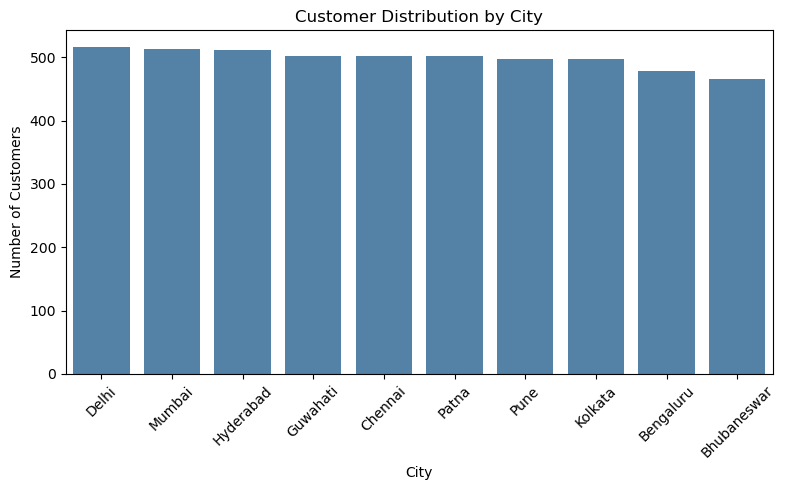

In [48]:
# Customer distribution by city

city_distribution = df["City"].value_counts()
print("Customer Distribution by City:")
print(city_distribution)
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="City",order=df["City"].value_counts().index,color="steelblue")

plt.title("Customer Distribution by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Customer Distribution by Gender:
Gender
Male      2992
Female    1996
Name: count, dtype: int64

Gender Distribution Percentage:
Gender
Male      59.98
Female    40.02
Name: proportion, dtype: float64


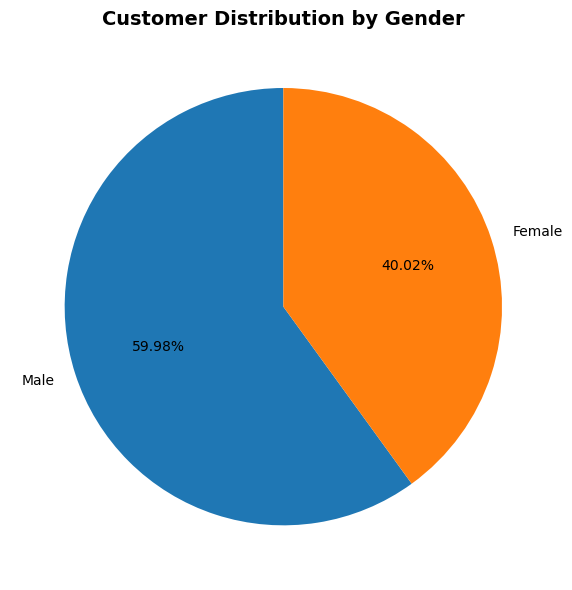

In [50]:
# Customer Distribution by Gender

gender_distribution = df["Gender"].value_counts()

print("Customer Distribution by Gender:")
print(gender_distribution)

print("\nGender Distribution Percentage:")
print(df["Gender"].value_counts(normalize=True).mul(100).round(2))
plt.figure(figsize=(8, 6))
plt.pie(gender_distribution,labels=gender_distribution.index,autopct="%1.2f%%",startangle=90)

plt.title("Customer Distribution by Gender",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()

Customer Distribution by Segment:
Customer_segment
Mass Market    3114
Affluent       1366
Premium         508
Name: count, dtype: int64

Customer Segment Percentage:
Customer_segment
Mass Market    62.43
Affluent       27.39
Premium        10.18
Name: proportion, dtype: float64


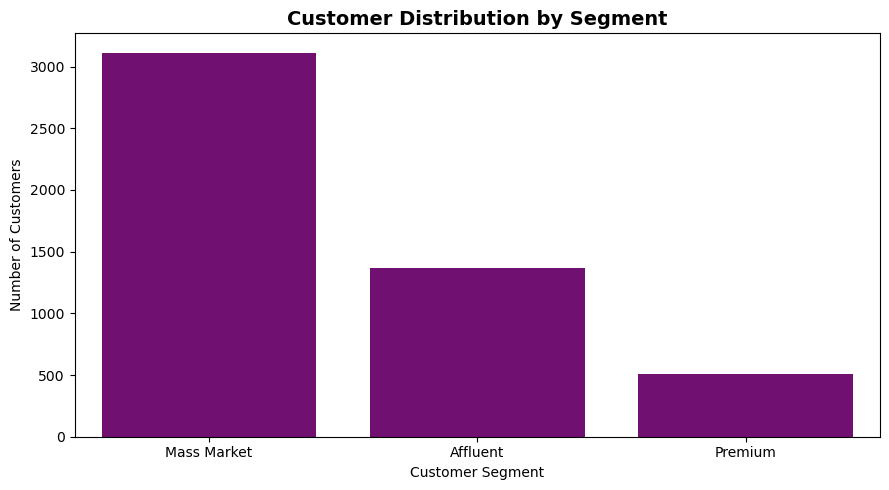

In [54]:
# Customer Distribution by Segment

segment_distribution = df["Customer_segment"].value_counts()
print("Customer Distribution by Segment:")
print(segment_distribution)
print("\nCustomer Segment Percentage:")
print(df["Customer_segment"].value_counts(normalize=True).mul(100).round(2))
plt.figure(figsize=(9, 5))
sns.barplot(x=segment_distribution.index,y=segment_distribution.values,color="purple")
plt.title("Customer Distribution by Segment",fontsize=14,fontweight="bold")

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Credit Score Summary Statistics:
count    4988.00
mean      734.21
std        61.93
min       550.00
25%       690.00
50%       735.00
75%       778.25
max       850.00
Name: Credit_score, dtype: float64

Average Credit Score: 734.21
Median Credit Score: 735.0


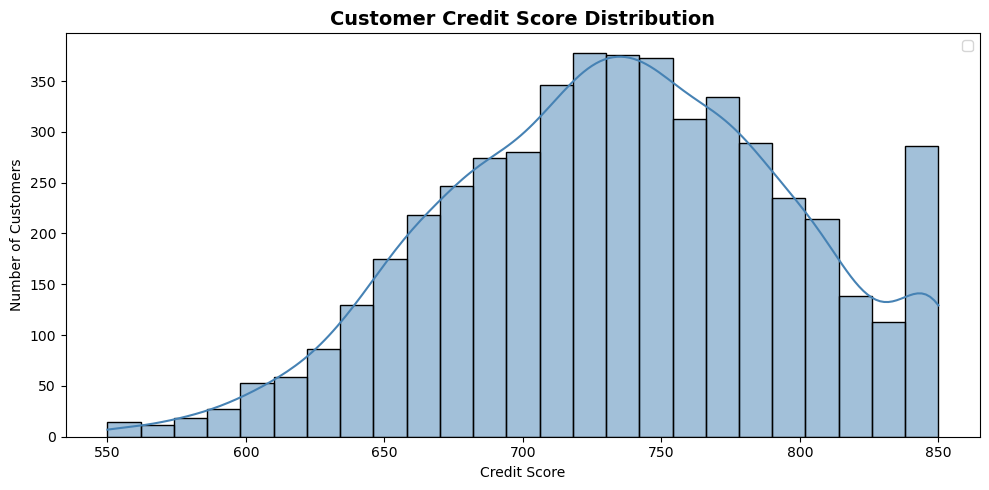

In [56]:
# Credit Score Distribution Analysis

print("Credit Score Summary Statistics:")
print(df["Credit_score"].describe().round(2))
print("\nAverage Credit Score:",round(df["Credit_score"].mean(), 2))
print("Median Credit Score:",df["Credit_score"].median())

plt.figure(figsize=(10, 5))
sns.histplot(data=df,x="Credit_score",bins=25,kde=True,color="steelblue")

plt.title("Customer Credit Score Distribution",fontsize=14,fontweight="bold")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()